## EDA on Limfadd dataset

Link:

https://www.tapadhirdas.com/das-lab/datasets/limfadd

### The 4 V's Assessment

#### **1. Volume**
- **Dataset Scale:** 15,000 rows × 11 columns (~744 KB)
- **Memory Footprint:** Light dataset that easily fits entirely into memory for rapid analysis and training.

#### **2. Velocity**
- **Current Dataset:** Static batch dataset without temporal/timestamp features.
- **Production Context:** High velocity in real-world deployment (new user accounts created continuously per second).

#### **3. Variety**
Structured data featuring a mix of numerical, categorical, and multi-class target attributes:

* **Numerical Features:**
  - Followers
  - Following
  - Link
  - Mutual Friends

* **Categorical Features:**
  - Bio
  - Profile Picture
  - External Link
  - Threads

* **Target Classification Labels:**
  1. Bot
  2. Scam
  3. Spam
  4. Real


#### **4. Veracity**
- **Ground Truth Quality:** High label integrity with an equal split of 3,750 samples across all 4 target classes established through domain research.
- **Formatting & Noise Issues (Discovered in EDA):**
  - **Inconsistent Data Types:** `Following/Followers` and `Posts/Followers` columns are stored as strings due to division-by-zero errors (`#DIV/0!`).
  - **Inconsistent Data Values:** Categorical variables contain mixed representations (e.g., `'N'`, `'yes'`, and `'Yes'`).
  - **Extreme Skewness & Outliers:** `Followers` ranges from `0` to `163,000`. This requires transformation

> **Synthetic Data Risk (LIMFADD Dataset)**
> LIMFADD utilizes LLM-based synthetic data expansion to reach 15,000 samples. While this improves statistical power and balances target classes, synthetic generation risks introducing artificial patterns that may not fully capture live real-world bot behavior. To ensure generalization, models evaluated on LIMFADD should ideally be cross-validated against real-world profile datasets.



### 4 V's Assessment Summary

| Dimension | Current Dataset | Production & Feature Breakdown |
| :--- | :--- | :--- |
| **Volume** | **15,000 rows** × **11 columns** (744 KB) | Low volume; easily fits into memory for single-node processing. |
| **Velocity** | Static snapshot (no timestamps) | High velocity in live production due to rapid real-time account creation. |
| **Variety** | Structured multi-modal dataset | **Numerical:** Followers, Following, Link, Mutual Friends<br>**Categorical:** Bio, Profile Picture, External Link, Threads<br>**Target Labels:** `Bot`, `Scam`, `Spam`, `Real` |
| **Veracity** | High label integrity (3,750 samples/class)<br>**Data Noise:** `#DIV/0!` string values, inconsistent data values (`'N'`, `'yes'`, `'Yes'`), extreme skewness in `Followers` | Expanded via LLM synthetic generation (LIMFADD).<br> *Must be cross-validated against real-world datasets.* |


In [18]:
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt
import numpy as np

In [19]:
df = pd.read_csv("..\Datasets\LIMFADD.csv")

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
C:\Users\filip\AppData\Local\Temp\ipykernel_39560\4165741346.py:1: SyntaxWarning: invalid escape sequence '\D'
  df = pd.read_csv("..\Datasets\LIMFADD.csv")


In [20]:
df.head()

,Followers,Following,Following/Followers,Posts,Posts/Followers,Bio,Profile Picture,External Link,Mutual Friends,Threads,Labels
0,2,2757,1378.5,0,0,N,N,N,0,N,Bot
1,2,505,252.5,0,0,N,Yes,N,0,N,Scam
2,6786,1782,0.262599469,1589,6051.040404,yes,N,Yes,10,N,Real
3,21,1281,61,0,0,N,Yes,N,0,N,Bot
4,585,1682,2.875213675,2663,926.1920333,yes,N,N,12,Yes,Real


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Followers            15000 non-null  int64
 1   Following            15000 non-null  int64
 2   Following/Followers  15000 non-null  str  
 3   Posts                15000 non-null  int64
 4   Posts/Followers      15000 non-null  str  
 5   Bio                  15000 non-null  str  
 6   Profile Picture      15000 non-null  str  
 7   External Link        15000 non-null  str  
 8   Mutual Friends       15000 non-null  int64
 9   Threads              15000 non-null  str  
 10  Labels               15000 non-null  str  
dtypes: int64(4), str(7)
memory usage: 1.3 MB


#### Check label balance

In [22]:
df["Labels"].value_counts()

Labels
Bot     3750
Scam    3750
Real    3750
Spam    3750
Name: count, dtype: int64

In [6]:
df.shape

(15000, 11)

In [7]:
df.describe()

,Followers,Following,Posts,Mutual Friends
count,15000.000000,15000.000000,15000.000000,15000.000000
mean,23397.378933,1385.350000,427.830200,3.011733
std,41920.419061,1600.823163,678.889037,4.203313
min,0.000000,0.000000,0.000000,0.000000
25%,6.000000,369.000000,1.000000,0.000000
50%,48.000000,725.500000,4.000000,0.000000
75%,19535.250000,1747.000000,578.250000,6.000000
max,163000.000000,6692.000000,2669.000000,15.000000


#### Convert ratios to numeric, coercing errors (#DIV/0! or invalid strings) to NaN


In [24]:
df['Following/Followers'] = pd.to_numeric(df['Following/Followers'], errors='coerce')
df['Posts/Followers'] = pd.to_numeric(df['Posts/Followers'], errors='coerce')

# Check how many NaNs were created by conversion
print(df[['Following/Followers', 'Posts/Followers']].isnull().sum())


Following/Followers    562
Posts/Followers        566
dtype: int64


#### Standardize Inconsistencies in cateogrical labels

In [ ]:
cat_cols = ['Bio', 'Profile Picture', 'External Link', 'Threads', 'Labels']
for col in cat_cols:
    print(df[col].unique())

<StringArray>
['N', 'yes', 'Yes']
Length: 3, dtype: str
<StringArray>
['N', 'Yes']
Length: 2, dtype: str
<StringArray>
['N', 'Yes']
Length: 2, dtype: str
<StringArray>
['N', 'Yes']
Length: 2, dtype: str
<StringArray>
['Bot', 'Scam', 'Real', 'Spam']
Length: 4, dtype: str


In [31]:
# Standardize text columns to uniform case ('Yes' / 'No')
cat_cols = ['Bio', 'Profile Picture', 'External Link', 'Threads']
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip().str.capitalize()
    df[col] = df[col].replace(to_replace='N', value='No')
    print(col, df[col].unique())

Bio <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Profile Picture <StringArray>
['No', 'Yes']
Length: 2, dtype: str
External Link <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Threads <StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [33]:
print("Missing values per column:\n", df.isnull().sum())

Missing values per column:
 Followers                0
Following                0
Following/Followers    562
Posts                    0
Posts/Followers        566
Bio                      0
Profile Picture          0
External Link            0
Mutual Friends           0
Threads                  0
Labels                   0
dtype: int64


In [34]:
print("Duplicate rows count:", df.duplicated().sum())

Duplicate rows count: 59


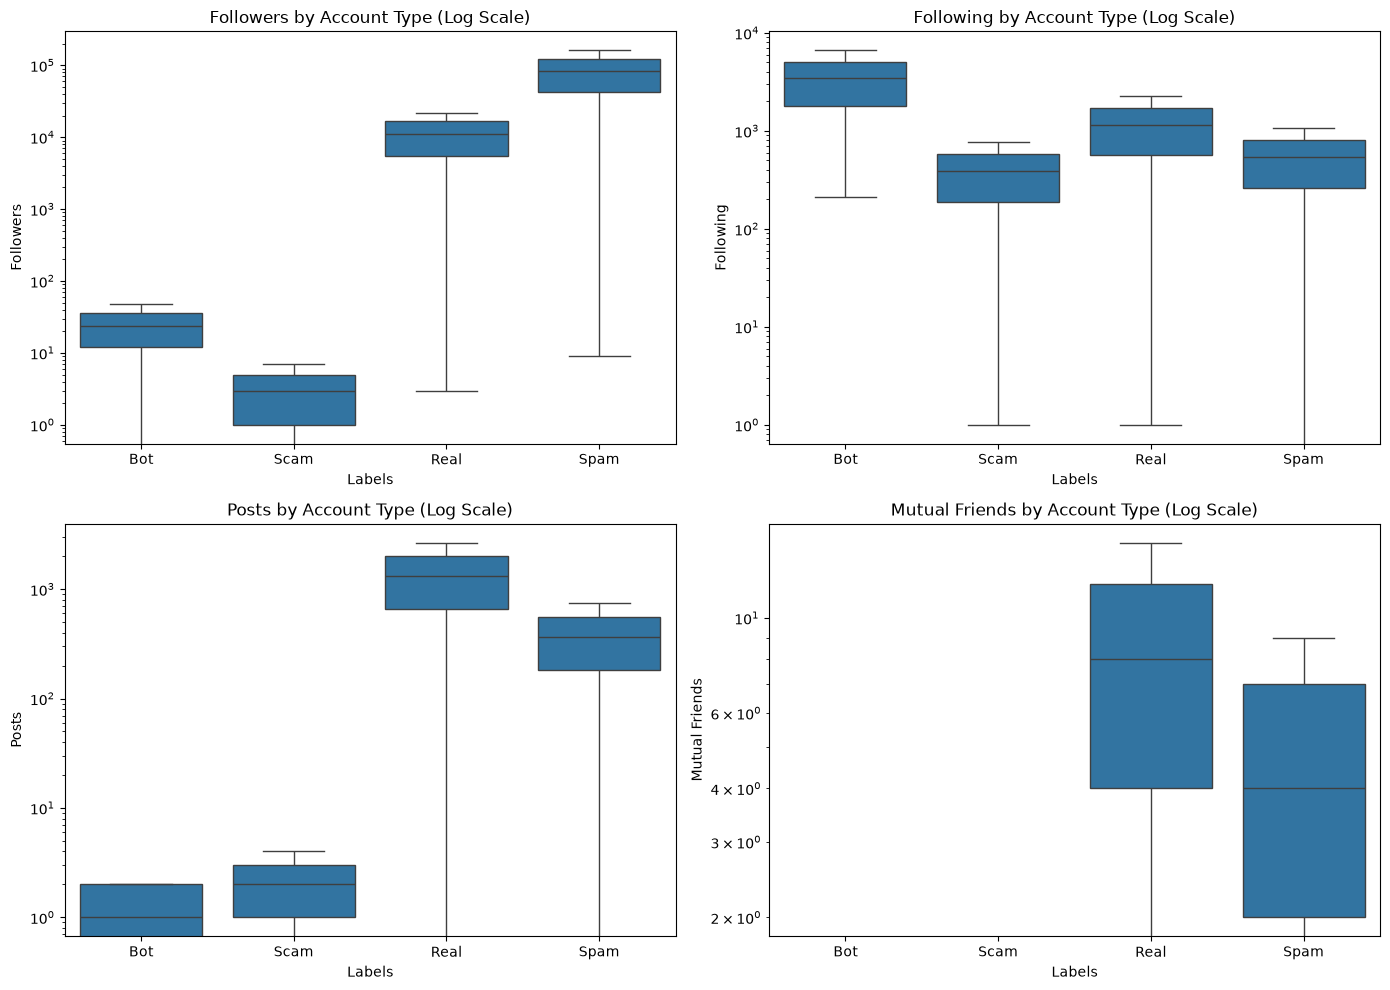

In [35]:
num_cols = ['Followers', 'Following', 'Posts', 'Mutual Friends']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flatten(), num_cols):
    sn.boxplot(data=df, x='Labels', y=col, ax=ax)
    ax.set_yscale('log') # Log scale handles the extreme skewness
    ax.set_title(f'{col} by Account Type (Log Scale)')
plt.tight_layout()
plt.show()



--- Bio (% within each label) ---
Labels    Bot   Real   Scam   Spam
Bio                               
No      100.0  31.65  49.31  49.44
Yes       0.0  68.35  50.69  50.56


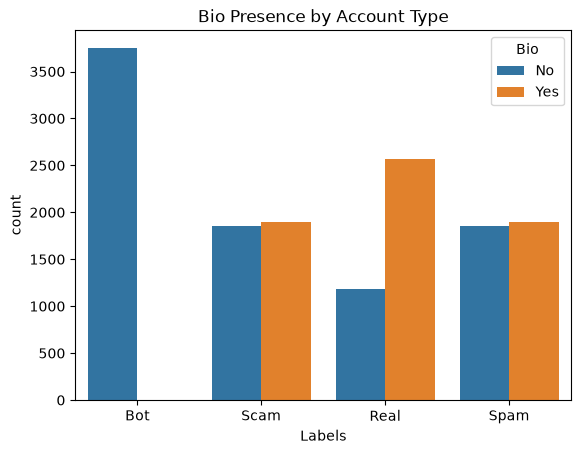


--- Profile Picture (% within each label) ---
Labels             Bot   Real   Scam   Spam
Profile Picture                            
No               51.79  50.61  50.08  48.75
Yes              48.21  49.39  49.92  51.25


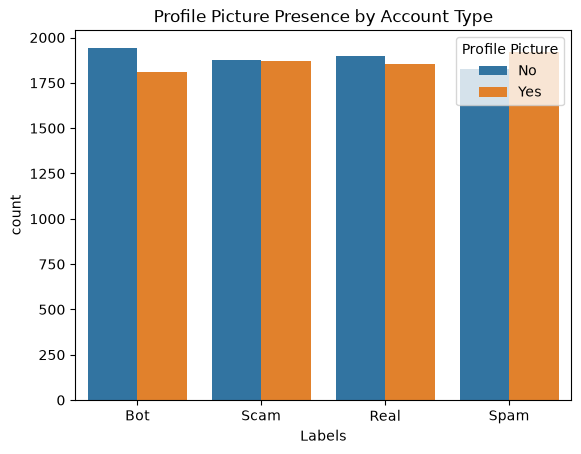


--- External Link (% within each label) ---
Labels           Bot   Real   Scam  Spam
External Link                           
No             100.0  50.72  100.0  48.4
Yes              0.0  49.28    0.0  51.6


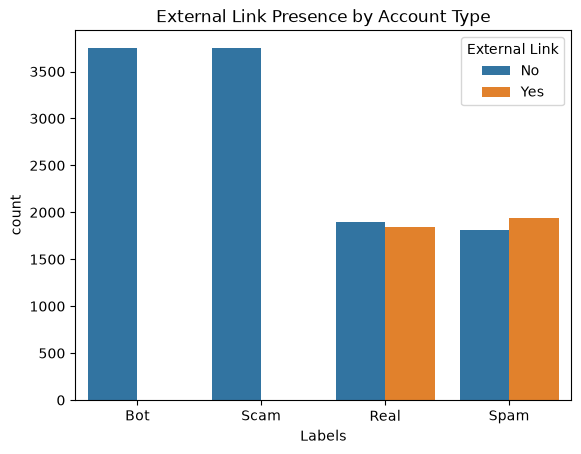


--- Threads (% within each label) ---
Labels     Bot   Real   Scam   Spam
Threads                            
No       100.0  49.36  100.0  49.52
Yes        0.0  50.64    0.0  50.48


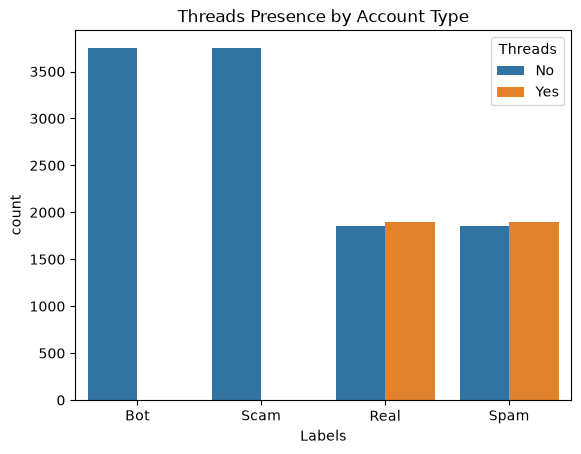

In [36]:
for col in ['Bio', 'Profile Picture', 'External Link', 'Threads']:
    ct = pd.crosstab(df[col], df['Labels'], normalize='columns') * 100
    print(f"\n--- {col} (% within each label) ---")
    print(ct.round(2))

    # Visualizing proportion of 'Yes' across account types
    sn.countplot(data=df, x='Labels', hue=col)
    plt.title(f'{col} Presence by Account Type')
    plt.show()


In [37]:
# Percentage of zero posts across labels
zero_posts = df.groupby('Labels')['Posts'].apply(lambda x: (x == 0).mean() * 100)
print("Percentage of accounts with 0 Posts:\n", zero_posts.round(2))

# Percentage of zero mutual friends across labels
zero_mutual = df.groupby('Labels')['Mutual Friends'].apply(lambda x: (x == 0).mean() * 100)
print("\nPercentage of accounts with 0 Mutual Friends:\n", zero_mutual.round(2))


Percentage of accounts with 0 Posts:
 Labels
Bot     32.75
Real     0.05
Scam    19.55
Spam     0.13
Name: Posts, dtype: float64

Percentage of accounts with 0 Mutual Friends:
 Labels
Bot     100.00
Real      5.95
Scam    100.00
Spam     10.08
Name: Mutual Friends, dtype: float64


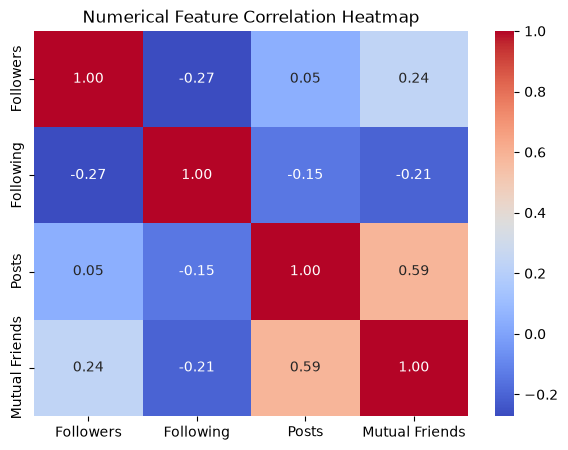

In [38]:
numeric_df = df[['Followers', 'Following', 'Posts', 'Mutual Friends']].copy()
plt.figure(figsize=(7, 5))
sn.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Numerical Feature Correlation Heatmap')
plt.show()
